# KD debug run (temporary: delete when done)

A cut-down copy of [`kd_e0_e3.ipynb`](kd_e0_e3.ipynb), to check on a laptop that every
part of the pipeline works before the full runs on the cluster. It runs each part
**once**: the teacher and its "other" shift, the teacher heads, a baseline, and KD.
About **an hour on a CPU**. Stop at the end; E1 onwards only repeats these parts with
more settings.

What changes from the main notebook:

| Section | Main notebook | Here |
|---|---|---|
| Mode | local trial without CUDA, full runs on CUDA | always the local trial (short budgets) |
| E0a | every teacher | only the KD teacher (ResNet-50) |
| E0b | `FAST`, `MAIN` ×seeds and `LONG` per student | only the `FAST` run (3 short epochs) |
| E0c | KD check for 3 teacher variants | only the linear head |
| SGD learning rate (ResNet-18) | 0.1, set for batches of 256 | 0.025: scaled to the local trial's batches of 64 |
| Results | `runs/local/...` | `runs/debug/...` |
| Extra | | one ViT-Ti baseline over 3 **full** epochs (~5 min) |

**Learning rate.** The local trial trains on batches of 64, but SGD's learning rate
(0.1) is set for 256. At 4× the effective step size, ResNet-18's loss spiked (to 20–30)
as one-cycle raised the rate. Here it is scaled linearly with the batch size,
$0.1 \times 64/256 = 0.025$ (Goyal et al., 2017). AdamW (ViT-Ti) is far less sensitive
to batch size, so its rate is kept.

Since its settings differ from the main notebook's local trial, the results go to their
own folder, `runs/debug/`, and never get mixed up with `runs/local/`. Keep the Mac awake
(e.g. start Jupyter with `caffeinate -dimsu jupyter lab`).

**What "working" looks like**

- E0a: ResNet-50 val balanced accuracy ≈ 0.69 with the shift, lower without it.
- E0c heads: linear head ≈ 0.81, with similar train and val confidence.
- Students after 90 steps sit at chance (≈ 0.09 balanced accuracy, 1/11): judge them by
  their **loss falling** (plotted below), not their accuracy.
- The full-epoch ViT-Ti run should be clearly above chance: proof that training learns.

## Setup

`lwfm` and `experiments` aren't installed packages, so the repository root goes on the
import path. Open this notebook from `experiments/kd/`.

All the choices for the notebook are in the second cell:

- **How much to run**: three modes, from cheapest to full.
  - `SMOKE = True`: checks the wiring of every cell in a few minutes. Random weights,
    two training steps per run, one validation batch of 8 images; writes to
    `runs/smoke/`. Its numbers mean nothing.
  - `LOCAL_TRIAL` (on by default without a CUDA GPU): the real pipeline, with real
    weights and data, but with short budgets. 3 / 6 / 10 epochs instead of 25 / 100 / 300, each epoch
    capped at 30 steps of 64 images, evaluation on 1,024 random images, and 1 seed.
    It writes to `runs/local/`. Roughly a day on a laptop CPU. Its numbers are a first
    look, not results.
  - both `False` (the default on a CUDA GPU, e.g. the cluster): the full experiments,
    25 / 100 / 300 epochs and 3 seeds, written to `runs/`. On a CPU they would take
    months.
- **Device**: `pick_device()` picks CUDA, then MPS (Mac GPU), then the CPU. A file
  `.kd-device` at the repository root holding e.g. `cpu` overrides it. It is listed in
  `.git/info/exclude`, so it is never committed.
- **`SPLIT`**: which classes are used.
  - **10 + 40** (default): the 10 named classes plus 40 random "other" classes. Runs
    are ~4× faster, and the teacher's "other" signal is cleaner (see E0a).
  - **10 + 190**: the notebook split, with all 190 other classes in "other". It is
    closer to the class imbalance expected in whole-slide images, so use it to
    confirm the final results.
- **`DATASET`**: to move to ImageNet-1k, do these once:
  ```
  python download/download_data.py imagenet-1k data/imagenet-1k   # ~140 GB
  ```
  ```python
  SPLIT = make_split("imagenet-1k", train_fraction=0.96, exist_ok=True).name
  ```
  then set `DATASET = "imagenet-1k"`. The rest follows from its entry in
  `parts.DATASETS`:
  - 224 px images with ImageNet augmentation
  - the standard ResNet-18 stem and ViT patch 16
  - no "other" class, so the teacher's 1000 logits are used unchanged
  - class weights of 1, top-5 added to the metrics, weight decay 1e-4
- **`STUDENTS_TO_RUN`**: every experiment runs once per student. A new student is one
  entry in `parts.STUDENTS`.

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd().resolve().parents[1]  # this notebook lives in experiments/kd/
sys.path.insert(0, str(REPO))

In [2]:
import json
from dataclasses import replace
from functools import partial

import matplotlib.pyplot as plt
import pandas as pd
import torch

from experiments.kd.parts import (
    DIST,
    DKD,
    FAST,
    KD,
    LOCAL,
    LOCAL_FAST,
    LOCAL_LONG,
    LOCAL_MAIN,
    LONG,
    MAIN,
    RUNS,
    STUDENTS,
    TEACHERS,
    Setup,
    SplitData,
    ToStudentClasses,
    evaluate_teacher,
    fit_teacher_head,
    make_split,
    pick_device,
    results,
    run,
    tune_other_shift,
)
from experiments.kd.parts import (
    SMOKE as SMOKE_SETTINGS,
)
from lwfm.core.graph import ExecutionGraph
from lwfm.core.losses import LossComposer

device = pick_device()
SMOKE = False  # True: a few-minute check of the wiring (numbers mean nothing)
LOCAL_TRIAL = True  # debug: always the short budgets, even on a GPU
DATASET = "tiny-imagenet"
NAMED = [f"{i:03d}" for i in range(10)]  # Tiny ImageNet folders 000-009
SPLIT = make_split(
    DATASET, keep=NAMED, num_other=40, train_fraction=0.7, exist_ok=True
).name  # 10 + 40; written once, then reused
# SPLIT = "tiny-70-30_5504132"  # 10 + 190, from examples/imagenet-splits.ipynb
STUDENTS_TO_RUN = ["resnet18", "vit_ti"]  # a CNN and a ViT
TEACHER = "resnet50"

data = SplitData(DATASET, SPLIT, workers=0 if SMOKE else 8)
mode = "smoke" if SMOKE else "local" if LOCAL_TRIAL else None
# debug: its own folder, apart from the main notebook's local trial (runs/local),
# because its SGD learning rate differs (see student_kw below)
root = RUNS / ("debug" if mode == "local" else mode) if mode else RUNS
runs = root / data.name  # modes never mix their runs
SEEDS = (0, 1, 2) if mode is None else (0,)
if mode == "local":  # same budget shapes, far fewer epochs
    FAST, MAIN, LONG = LOCAL_FAST, LOCAL_MAIN, LOCAL_LONG

# Budgets: FAST (25 epochs, one-cycle) ranks settings in a sweep; MAIN (100 epochs,
# warmup + cosine) gives the reported results; LONG (300 epochs) checks whether KD's
# gain grows with training time. Each student adds its own optimiser settings, e.g.
# vit_ti trains with AdamW. Each run's manifest.json records the final settings.

# Passed to every run: device, pretrained teachers?, smoke overrides, results folder
overrides = {"smoke": SMOKE_SETTINGS, "local": LOCAL}.get(mode)
kw = dict(device=device, pretrained=not SMOKE, overrides=overrides, runs=runs)
eval_cfg = replace(MAIN, **(kw["overrides"] or {}))  # eval batch settings


def student_kw(student: str) -> dict:
    # debug: kw with SGD's learning rate scaled to the local trial's batch size.
    # The budget's lr (0.1) is set for batches of 256; at 64 it is 4x too large.
    base = Setup(student).train_config(FAST, data)  # without the local overrides
    if mode != "local" or base.optimizer != "sgd":
        return kw  # AdamW (vit_ti) keeps its lr
    lr = base.lr * LOCAL["batch_size"] / base.batch_size  # 0.1 x 64/256 = 0.025
    return kw | {"overrides": LOCAL | {"lr": lr}}


def show(pattern: str, sort: str = "eval/val/bal_acc") -> pd.DataFrame:
    # One row per completed run matching runs/<pattern>, best first
    columns = [
        "run",
        "student",
        "teacher_head",
        "other_shift",
        "eval/val/bal_acc",
        "eval/val/macro_f1",
        "eval/test/bal_acc",
        "eval/test/macro_f1",
        "eval/test/top1",
        "eval/test/top5",
        "train/epoch_seconds",
        "cost/params_m",
        "cost/gflops",
        "cost/latency_ms_median",
    ]
    df = pd.DataFrame(results(pattern, runs))
    return df[[c for c in columns if c in df]].sort_values(sort, ascending=False)


def logged(run_name: str, name: str) -> list:
    # Every value logged under `name` in one run, in order (e.g. a per-epoch curve)
    lines = (runs / run_name / "events.jsonl").read_text().splitlines()
    return [e["value"] for e in map(json.loads, lines) if e["name"] == name]


print(f"device: {device}, mode: {mode or 'full'}, results in {runs}")

device: cpu, mode: local, results in /Users/ashleywebb/Uni/yr4/imagenet-classification/runs/local/tiny-imagenet/tiny-imagenet-10+40other-70-30_5504132


## The data

Labels 0–9 are the 10 named classes; the last label is "other". "Other" makes up 80 %
of the 10 + 40 split and 95 % of the 10 + 190 split. Two things follow:

- **Training** uses class-weighted cross-entropy, $w_c = N / (C \cdot n_c)$, so a
  mistake on a rare class costs more. On a balanced dataset every weight is 1.
- **Selection and reporting** use **balanced accuracy**, the mean of the per-class
  recalls. Always predicting "other" scores 80–95 % plain accuracy, but only
  1/11 = 9.1 % balanced accuracy, the same as chance.

`val` is a hold-out from the train folder and is used for **every** choice. `test` is
the official validation set and is used only for the final numbers.

In [3]:
counts = {
    split: pd.Series([int(r["label"]) for r in data.rows(split)])
    .value_counts()
    .sort_index()
    for split in ("train", "val", "test")
}
print(
    f"{data.num_classes} classes, {data.spec.image_size} px, "
    f"{len(data.other_folders())} source classes in 'other'"
)
pd.DataFrame(
    {
        "folder": data.classes,
        "name": data.class_names(),
        **counts,
        "CE weight": data.class_weights().numpy().round(3),
    }
).head(20)

11 classes, 64 px, 40 source classes in 'other'


,folder,name,train,val,test,CE weight
0,000,goldfish,350,150,50,4.545
1,001,European fire salamander,350,150,50,4.545
2,002,bullfrog,350,150,50,4.545
3,003,tailed frog,350,150,50,4.545
4,004,American alligator,350,150,50,4.545
5,005,boa constrictor,350,150,50,4.545
6,006,trilobite,350,150,50,4.545
7,007,scorpion,350,150,50,4.545
8,008,black widow,350,150,50,4.545
9,009,tarantula,350,150,50,4.545


## How a run is put together

A `Setup` names the parts of one run, and `setup.build(data)` turns them into lwfm
graph nodes and loss bindings:

- **student**: a model from `parts.STUDENTS`, built for the dataset's image size. It
  outputs `student.logits` and `student.embed` (the pooled feature before the
  classifier).
- **teacher** (only when a KD loss needs it): frozen. It reads the **same augmented
  image** as the student, resized to 224 px, so both see the same crop and flip. Its
  1000 ImageNet logits are mapped to the student's classes:
  - the named classes keep their own logits;
  - the ImageNet classes behind "other" are merged into one logit, minus a prior
    correction `other_shift` (chosen in E0a);
  - every other ImageNet class is dropped.
- **projector** (only for an embedding loss): `Linear(student dim → teacher dim) +
  LayerNorm`. It is used only in training, so it is never saved or counted in the
  student's cost.
- **losses**: weighted CE, plus the chosen KD loss. Each loss class lists the values it
  reads, e.g. `KD.reads == ["student.logits", "teacher.logits"]`.

Swapping the dataset, teacher, student or loss is a change to one argument. Here is an
E1 setup for each student, built with random weights only to show the wiring:

In [4]:
batch = next(iter(data.loader("val", 4)))
for student in STUDENTS_TO_RUN:
    setup = Setup(
        student, TEACHER, logit=partial(KD, T=4), alpha=0.9
    )  # 0.1·CE + 0.9·KD
    nodes, losses = setup.build(data, pretrained=False)
    graph = ExecutionGraph(nodes)
    print(student, graph.preflight(batch))
for b in losses:
    print(f"loss {b.name}: weight {b.weight}, reads {b.inputs}")
print("students:", list(STUDENTS), "| teachers:", list(TEACHERS))

resnet18 {'student.logits': (4, 11), 'student.embed': (4, 512), 'teacher.logits': (4, 11), 'teacher.embed': (4, 2048)}
vit_ti {'student.logits': (4, 11), 'student.embed': (4, 192), 'teacher.logits': (4, 11), 'teacher.embed': (4, 2048)}
loss ce: weight 0.1, reads ['student.logits', 'targets.class']
loss KD: weight 0.9, reads ['student.logits', 'teacher.logits']
students: ['resnet18', 'vit_ti'] | teachers: ['resnet50', 'resnet34', 'vit_b16', 'vit_b16_swag', 'dinov2_b14']


### Sanity checks

These run in seconds and must pass before training anything:

1. With no shift, mapping the teacher's logits gives the same probabilities as a
   softmax over just the split's classes, with "other" as the sum of its classes.
2. Identical student and teacher logits give KD, DKD and DIST ≈ 0. DIST is ~1e-3
   rather than 0, because of a small ε that keeps it numerically stable.
3. After `backward()`, the frozen teacher has no gradients, while the student does.

In [5]:
# 1. Teacher logits -> student classes
keep, other = data.teacher_classes(), data.teacher_other_classes()
z = torch.randn(4, 1000)
p_split = z[:, keep + other].softmax(
    1
)  # the teacher, restricted to the split's classes
p = ToStudentClasses(keep, other or None, shift=0.0)({"logits": z})["logits"].softmax(1)
assert torch.allclose(p[:, : len(keep)], p_split[:, : len(keep)], atol=1e-6)
if other:
    assert torch.allclose(p[:, -1], p_split[:, len(keep) :].sum(1), atol=1e-6)

# 2. Identical logits -> ~0 loss
z, y = torch.randn(8, data.num_classes), torch.randint(0, data.num_classes, (8,))
print(f"KD {KD()(z, z):.2e}, DKD {DKD()(z, z, y):.2e}, DIST {DIST()(z, z):.2e}")

# 3. Gradients reach the student only (graph and losses from the cell above)
total, terms = LossComposer(losses)(batch, graph(batch))
total.backward()
assert all(p.grad is None for p in graph.nodes["teacher"].parameters())
assert all(p.grad is not None for p in graph.nodes["student"].parameters())
print(
    "all checks passed; loss terms:", {k: round(v.item(), 3) for k, v in terms.items()}
)

KD -2.98e-07, DKD -3.26e-09, DIST 6.56e-07
all checks passed; loss terms: {'ce': 2.398, 'KD': 26.732}


## E0a: The teachers alone (inference only, no training)

Each teacher is scored exactly as it is used in KD: on the student's images resized to
224 px (upsampled from 64 px on Tiny ImageNet), with its logits mapped to the student's
classes. **Nothing is trained here.**

**Why the "other" logit needs correcting.** A softmax treats all its classes as equally
likely in advance. Merging $n$ classes into "other" therefore makes "other" $n$ times
likelier than a named class before the image is even seen. On blurry upsampled 64 px
images the teacher is unsure, so this prior wins, and the teacher calls most
named-class images "other". Measured on val with ResNet-50:

| Split | Teacher, no correction (bal. acc / macro-F1) | Teacher, tuned correction |
|---|---|---|
| 10 + 40 | 0.51 / 0.58 | 0.69 / 0.69 |
| 10 + 190 | 0.37 / 0.44 | 0.61 / 0.61 |

The fix subtracts a constant from the merged logit: $z_\text{other} =
\operatorname{logsumexp}(z_\text{other classes}) - b$.

- $b = \log n$ gives "other" the same prior as each named class. That maximises
  balanced accuracy, but it pulls "other" images towards the named classes.
- So $b$ is **chosen on val by macro-F1**, which also counts that loss of precision,
  once per teacher, from a single pass of the teacher.

Fewer "other" classes also means less to correct, which is one reason the 10 + 40 split
gives the cleaner teacher.

All teachers come from torchvision, except DINOv2, which downloads its code and weights
from GitHub through `torch.hub`. The teachers' accuracy here is optimistic, because
Tiny ImageNet's images come from ImageNet's training set.

In [6]:
shifts = {}  # teacher -> chosen other_shift (None when there is no "other" class)
for teacher in [TEACHER]:  # debug: the KD teacher only (others are slow on CPU)
    if SMOKE and teacher == "dinov2_b14":
        continue  # needs network access even with random weights
    if data.has_other:
        rows = tune_other_shift(
            teacher,
            data,
            device,
            pretrained=not SMOKE,
            eval_batches=eval_cfg.eval_batches,
            batch_size=eval_cfg.eval_batch_size,
        )
        shifts[teacher] = max(rows, key=lambda r: r["macro_f1"])["shift"]
        if teacher == TEACHER:
            display(pd.DataFrame(rows).round(3))  # the trade-off for the KD teacher
    else:
        shifts[teacher] = None
    evaluate_teacher(
        f"teachers/{teacher}/logits", teacher, data, other_shift=shifts[teacher], **kw
    )
if data.has_other:  # for comparison in E0c: the KD teacher with no correction at all
    evaluate_teacher(
        f"teachers/{TEACHER}/logits-no-shift", TEACHER, data, other_shift=0.0, **kw
    )
print("chosen shifts:", shifts)
show("teachers/*/logits")

,shift,bal_acc,macro_f1,p_other_on_other
0,0.000,0.524,0.589,0.925
1,0.461,0.594,0.633,0.892
2,0.922,0.632,0.661,0.847
3,1.383,0.668,0.681,0.790
4,1.844,0.711,0.709,0.721
5,2.306,0.737,0.720,0.643
6,2.767,0.748,0.710,0.560
7,3.228,0.748,0.676,0.475
8,3.689,0.746,0.593,0.393
9,4.150,0.737,0.501,0.315


eval/val/bal_acc = 0.7374
eval/val/macro_f1 = 0.7204
eval/val/top1 = 0.917
eval/test/bal_acc = 0.7004
eval/test/macro_f1 = 0.6769
eval/test/top1 = 0.9043
test/per_class_recall = {'000': 1.0, '001': 0.8666666746139526, '002': 0.0625, '003': 1.0, '004': 0.3478260934352875, '005': 0.4166666567325592, '006': 0.9411764740943909, '007': 0.7777777910232544, '008': 0.9130434989929199, '009': 0.4166666567325592, 'other': 0.962469756603241}
cost/params_m = 25.56
cost/size_mb = 102.5
cost/gflops = 8.178
cost/latency_ms_median = 13.52
cost/latency_ms_p95 = 14.09
status = completed
eval/val/bal_acc = 0.5241
eval/val/macro_f1 = 0.5894
eval/val/top1 = 0.8906
eval/test/bal_acc = 0.5276
eval/test/macro_f1 = 0.5818
eval/test/top1 = 0.8936
test/per_class_recall = {'000': 0.9545454382896423, '001': 0.8666666746139526, '002': 0.0625, '003': 0.6875, '004': 0.21739129722118378, '005': 0.2083333283662796, '006': 0.5882353186607361, '007': 0.4444444477558136, '008': 0.6521739363670349, '009': 0.125, 'other': 0

,run,teacher_head,other_shift,eval/val/bal_acc,eval/val/macro_f1,eval/test/bal_acc,eval/test/macro_f1,eval/test/top1,cost/params_m,cost/gflops,cost/latency_ms_median
0,teachers/resnet50/logits,None,2.306,0.737411,0.720412,0.700436,0.676937,0.904297,25.557032,8.178369,13.520146


In [7]:
# Test recall per class (rows) for each teacher (columns)
recall = {
    d.name: logged(f"teachers/{d.name}/logits", "test/per_class_recall")[0]
    for d in sorted((runs / "teachers").iterdir())
}
# Recalls are stored by folder id ("000"); show them by class name ("goldfish")
names = dict(zip(data.classes, data.class_names(), strict=True))
pd.DataFrame(recall).rename(index=names).round(3).head(20)

,resnet50
goldfish,NaN
European fire salamander,NaN
bullfrog,NaN
tailed frog,NaN
American alligator,NaN
boa constrictor,NaN
trilobite,NaN
scorpion,NaN
black widow,NaN
tarantula,NaN


## E0b: The baseline students (debug: `FAST` only)

Weighted CE only, no teacher. Here each student runs only the `FAST` budget (3 epochs of
30 steps in the local trial), the reference for the KD runs below.

In [8]:
for student in STUDENTS_TO_RUN:
    baseline = Setup(student)  # weighted CE only: no teacher, no KD loss
    run(
        f"no-teacher/e0/{student}/sweep/baseline_s0",
        baseline,
        data,
        FAST,
        **student_kw(student),
    )
show("no-teacher/e0/*/*/*")

[fit step 1] train/loss/ce = 2.554
[fit step 1] train/loss/total = 2.554
[fit step 2] train/loss/ce = 2.513
[fit step 2] train/loss/total = 2.513
[fit step 3] train/loss/ce = 2.338
[fit step 3] train/loss/total = 2.338
[fit step 4] train/loss/ce = 2.75
[fit step 4] train/loss/total = 2.75
[fit step 5] train/loss/ce = 2.743
[fit step 5] train/loss/total = 2.743
[fit step 6] train/loss/ce = 2.26
[fit step 6] train/loss/total = 2.26
[fit step 7] train/loss/ce = 2.836
[fit step 7] train/loss/total = 2.836
[fit step 8] train/loss/ce = 4.08
[fit step 8] train/loss/total = 4.08
[fit step 9] train/loss/ce = 4.261
[fit step 9] train/loss/total = 4.261
[fit step 10] train/loss/ce = 3.651
[fit step 10] train/loss/total = 3.651
[fit step 11] train/loss/ce = 4
[fit step 11] train/loss/total = 4
[fit step 12] train/loss/ce = 5.371
[fit step 12] train/loss/total = 5.371
[fit step 13] train/loss/ce = 5.274
[fit step 13] train/loss/total = 5.274
[fit step 14] train/loss/ce = 3.389
[fit step 14] train/l

,run,student,eval/val/bal_acc,eval/val/macro_f1,eval/test/bal_acc,eval/test/macro_f1,eval/test/top1,train/epoch_seconds,cost/params_m,cost/gflops,cost/latency_ms_median
1,no-teacher/e0/vit_ti/sweep/baseline_s0,vit_ti,0.090909,0.003483,0.090909,0.003994,0.022461,27.52526,5.390603,0.694817,3.100500
0,no-teacher/e0/resnet18/sweep/baseline_s0,resnet18,0.082530,0.016591,0.091116,0.016053,0.042969,87.01054,11.174475,4.443352,6.751896


## E0c: Heads trained on the frozen teacher

Instead of mapping the teacher's ImageNet logits to our classes (E0a), train a small
**head** on the frozen teacher's embedding, with our labels. The backbone is unchanged;
only the head is new.

- It learns "other" as an ordinary class, so no merge and no shift are needed.
- It learns what upsampled 64 px images look like in the teacher's feature space,
  where the ImageNet head was trained on sharp 224 px photos.
- Pathology foundation models have no class head, so they need exactly this step.

Two kinds of head, both trained on embeddings cached from one pass of the teacher over
the un-augmented train and val images:

| Head | Why try it |
|---|---|
| `linear` | The features were trained for a linear head; few parameters, hard to overfit |
| `mlp` (one hidden layer of 512, dropout) | Can undo some of the distortion from upsampling, but overfits sooner |

Each is trained with class-weighted CE for a few weight decays, with early stopping, all
chosen by **val macro-F1**. The table also shows each head's **confidence** (mean top
probability) on train and val. A head that is near-certain on train images has memorised
them, so its soft targets add little beyond the labels, which weakens KD.

On ImageNet-1k this section is skipped: the teacher's own 1000-way head already matches
the classes.

In [9]:
HEAD_KINDS = ["linear", "mlp"] if data.has_other else []
head_rows = []
for kind in HEAD_KINDS:
    # Heads always use every train/val embedding (one teacher pass, then cached),
    # except in smoke mode, whose random-weight cache is kept separately
    head_rows += fit_teacher_head(
        TEACHER,
        data,
        device,
        kind,
        pretrained=not SMOKE,
        max_batches=eval_cfg.eval_batches if SMOKE else None,
        batch_size=eval_cfg.eval_batch_size,
    )
    evaluate_teacher(
        f"teachers/{TEACHER}/{kind}", TEACHER, data, teacher_head=kind, **kw
    )
pd.DataFrame(head_rows).round(3)  # one row per head and weight decay

eval/val/bal_acc = 0.8321
eval/val/macro_f1 = 0.8078
eval/val/top1 = 0.9404
eval/test/bal_acc = 0.8229
eval/test/macro_f1 = 0.7846
eval/test/top1 = 0.9355
test/per_class_recall = {'000': 1.0, '001': 0.9333333373069763, '002': 0.5, '003': 0.5625, '004': 0.695652186870575, '005': 0.8333333134651184, '006': 1.0, '007': 0.9444444179534912, '008': 0.8260869383811951, '009': 0.7916666865348816, 'other': 0.9648910164833069}
cost/params_m = 25.58
cost/size_mb = 102.6
cost/gflops = 8.178
cost/latency_ms_median = 13.58
cost/latency_ms_p95 = 14.11
status = completed
eval/val/bal_acc = 0.8484
eval/val/macro_f1 = 0.8407
eval/val/top1 = 0.9512
eval/test/bal_acc = 0.8458
eval/test/macro_f1 = 0.8355
eval/test/top1 = 0.957
test/per_class_recall = {'000': 1.0, '001': 0.9333333373069763, '002': 0.5625, '003': 0.5, '004': 0.782608687877655, '005': 0.8333333134651184, '006': 1.0, '007': 1.0, '008': 0.95652174949646, '009': 0.75, 'other': 0.9854721426963806}
cost/params_m = 26.61
cost/size_mb = 106.8
cost/g

,head,weight_decay,best_step,val_bal_acc,val_macro_f1,train_confidence,val_confidence,chosen
0,linear,0.01,1900,0.809,0.792,0.979,0.958,True
1,linear,0.10,2000,0.808,0.791,0.977,0.955,False
2,linear,1.00,1650,0.821,0.782,0.942,0.920,False
3,mlp,0.01,1400,0.814,0.819,1.000,0.986,False
4,mlp,0.10,1050,0.815,0.819,0.999,0.984,True
5,mlp,1.00,2000,0.814,0.819,0.999,0.979,False


### Comparing the teacher variants

**At teacher level:** each variant of the KD teacher, scored alone on val and test:

- `logits-no-shift`: the mapped ImageNet logits, uncorrected
- `logits`: the mapped ImageNet logits, with the shift from E0a
- `linear`, `mlp`: the trained heads

In [10]:
show(f"teachers/{TEACHER}/*")

,run,teacher_head,other_shift,eval/val/bal_acc,eval/val/macro_f1,eval/test/bal_acc,eval/test/macro_f1,eval/test/top1,cost/params_m,cost/gflops,cost/latency_ms_median
3,teachers/resnet50/mlp,mlp,NaN,0.848353,0.840699,0.845797,0.835475,0.957031,26.611763,8.180477,13.672541
0,teachers/resnet50/linear,linear,NaN,0.832051,0.807784,0.822901,0.784605,0.935547,25.579571,8.178414,13.580438
1,teachers/resnet50/logits,NaN,2.306,0.737411,0.720412,0.700436,0.676937,0.904297,25.557032,8.178369,13.520146
2,teachers/resnet50/logits-no-shift,NaN,0.000,0.524056,0.589442,0.527560,0.581838,0.893555,25.557032,8.178369,13.760041


**At student level (debug: linear head only):** the linear-head teacher teaches each
student with standard KD ($T = 4$, $\alpha = 0.9$) on the `FAST` budget. Compare with the
baselines above. After so few steps the accuracies are near chance, so look at the
losses in the next section.

In [11]:
variants = {"logits": dict(other_shift=shifts[TEACHER])}  # mapped ImageNet logits
variants = {"linear": dict(teacher_head="linear")}  # debug: one variant only

for variant, teacher_args in variants.items():
    for student in STUDENTS_TO_RUN:
        setup = Setup(
            student, TEACHER, logit=partial(KD, T=4), alpha=0.9, **teacher_args
        )
        run(
            f"{TEACHER}-{variant}/e0c/{student}/sweep/kd_T4_a0.9_s0",
            setup,
            data,
            FAST,
            **student_kw(student),
        )

check = pd.DataFrame(
    results("*/e0c/*/sweep/*", runs) + results("no-teacher/e0/*/sweep/*", runs)
)
check["teacher"] = check["run"].str.split("/").str[0]
check.pivot_table(index="teacher", columns="student", values="eval/val/bal_acc").round(
    4
)

[fit step 1] train/loss/ce = 2.554
[fit step 1] train/loss/KD = 13.17
[fit step 1] train/loss/total = 12.11
[fit step 2] train/loss/ce = 6.945
[fit step 2] train/loss/KD = 6.029
[fit step 2] train/loss/total = 6.12
[fit step 3] train/loss/ce = 10.24
[fit step 3] train/loss/KD = 6.383
[fit step 3] train/loss/total = 6.769
[fit step 4] train/loss/ce = 8.529
[fit step 4] train/loss/KD = 4.814
[fit step 4] train/loss/total = 5.186
[fit step 5] train/loss/ce = 8.069
[fit step 5] train/loss/KD = 5.234
[fit step 5] train/loss/total = 5.517
[fit step 6] train/loss/ce = 8.672
[fit step 6] train/loss/KD = 5.137
[fit step 6] train/loss/total = 5.491
[fit step 7] train/loss/ce = 6.303
[fit step 7] train/loss/KD = 6.835
[fit step 7] train/loss/total = 6.782
[fit step 8] train/loss/ce = 11.6
[fit step 8] train/loss/KD = 8.209
[fit step 8] train/loss/total = 8.548
[fit step 9] train/loss/ce = 3.986
[fit step 9] train/loss/KD = 30.21
[fit step 9] train/loss/total = 27.59
[fit step 10] train/loss/ce = 

student,resnet18,vit_ti
teacher,,
no-teacher,0.0825,0.0909
resnet50-linear,0.0909,0.0909


## Is training working?

The training loss of each run, per logged step. Every curve should fall. For KD runs,
`total` is $0.1 \cdot \mathrm{CE} + 0.9 \cdot \mathrm{KD}$, and each term is also
plotted.

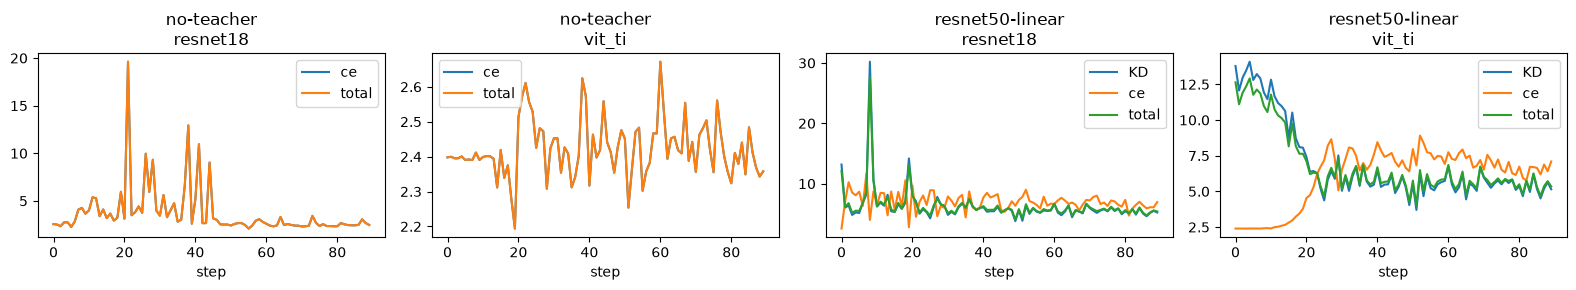

In [12]:
debug_runs = [
    f"no-teacher/e0/{student}/sweep/baseline_s0" for student in STUDENTS_TO_RUN
] + [
    f"{TEACHER}-linear/e0c/{student}/sweep/kd_T4_a0.9_s0" for student in STUDENTS_TO_RUN
]

fig, axes = plt.subplots(1, len(debug_runs), figsize=(4 * len(debug_runs), 3))
for ax, name in zip(axes, debug_runs, strict=True):
    events = [json.loads(line) for line in (runs / name / "events.jsonl").open()]
    for loss in sorted(
        {e["name"] for e in events if e["name"].startswith("train/loss/")}
    ):
        ax.plot([e["value"] for e in events if e["name"] == loss], label=loss[11:])
    ax.set(title=name.split("/", 1)[0] + "\n" + name.split("/")[-3], xlabel="step")
    ax.legend()
plt.tight_layout()

## Extra: does a student learn with more steps?

ViT-Ti is cheap on a CPU (≈ 0.2 s per step), so one baseline over 3 **full** epochs
(≈ 820 steps rather than 90) takes about 5 minutes. It should end clearly above chance
(0.09). It has its own run name (`debug/`), because its settings differ from the local
trial's.

In [13]:
full_epochs = kw | {"overrides": LOCAL | {"max_steps": None}}  # no 30-step cap
run(
    "no-teacher/e0/vit_ti/full-epochs/baseline_s0",
    Setup("vit_ti"),
    data,
    FAST,
    **full_epochs,
)
show("no-teacher/e0/vit_ti/*/*")  # the 90-step run above and this one

[fit step 50] train/loss/ce = 2.287
[fit step 50] train/loss/total = 2.287
[fit step 100] train/loss/ce = 2.372
[fit step 100] train/loss/total = 2.372
[fit step 150] train/loss/ce = 2.343
[fit step 150] train/loss/total = 2.343
[fit step 200] train/loss/ce = 2.155
[fit step 200] train/loss/total = 2.155
[fit step 250] train/loss/ce = 2.327
[fit step 250] train/loss/total = 2.327
[fit step 273] train/epoch_seconds = 84.94
[fit step 273] train/lr = 0.001988
[step 273] eval/val/bal_acc = 0.09881
[step 273] eval/val/macro_f1 = 0.01555
[step 273] eval/val/top1 = 0.02246
[fit step 300] train/loss/ce = 2.468
[fit step 300] train/loss/total = 2.468
[fit step 350] train/loss/ce = 2.445
[fit step 350] train/loss/total = 2.445
[fit step 400] train/loss/ce = 2.42
[fit step 400] train/loss/total = 2.42
[fit step 450] train/loss/ce = 2.436
[fit step 450] train/loss/total = 2.436
[fit step 500] train/loss/ce = 2.44
[fit step 500] train/loss/total = 2.44
[fit step 546] train/epoch_seconds = 85.38
[fi

,run,student,eval/val/bal_acc,eval/val/macro_f1,eval/test/bal_acc,eval/test/macro_f1,eval/test/top1,train/epoch_seconds,cost/params_m,cost/gflops,cost/latency_ms_median
0,no-teacher/e0/vit_ti/sweep/baseline_s0,vit_ti,0.090909,0.003483,0.090909,0.003994,0.022461,27.52526,5.390603,0.694817,3.1005
